# Split test: does ensemble diversity come from the data cuts or the pre-trained starts?

The `noisytrain` run scored worse than the baseline, with larger scatter and narrower, worse-calibrated p(z)s. Between the two runs the members lost two sources of diversity at once:

| run | data cut | pre-trained start | training photometry |
|---|---|---|---|
| `baseline` | K-fold: member k validates on fold k | member k from pop-cosmos member k | catalogue, as given |
| `noisytrain` | one shared cut | all from pop-cosmos member 0 | own noise realization per member |

This notebook separates the first two on the configuration that degraded most (task set 3, cardinal, 10yr). It compares four ensembles:

- `baseline` and `noisytrain`: the saved models, re-evaluated here.
- `kfold_samestart`, **the test**: K-fold cuts, every member from pop-cosmos member 0, catalogue photometry.
- `kfold_cyclestart`, **the reference**: the baseline's settings retrained. Training is not deterministic, so its gap to the saved `baseline` is the run-to-run noise. Differences smaller than that gap are not significant.

How to read it:
- If `kfold_samestart` is close to `baseline`/`kfold_cyclestart`, the K-fold cuts are what pays off and the starting point does not matter.
- If it is close to `noisytrain`, the different pre-trained starts are what pays off.

All four are scored on the same held-out objects (the `VAL_FRAC`, `SEED` split of the task-set notebooks, never used in training) and predicted the same way: `znn.ensemble_predict_resampled` with `N_SAMPLES` noise draws from the same seed, giving a Gaussian p(z) per object. Besides the challenge metrics, the table splits each p(z) width into the members' disagreement ("model σ") and the spread over noise draws ("photometric σ"), which shows the diversity directly.

Run this from the repo root on NERSC with the `qp` conda env as the kernel. Trained models and predictions are saved in `TEST_DIR`, so a rerun skips what is done.

## Configuration

In [1]:
import os

from rail.utils.path_utils import find_rail_file

import znn  # run from the repo root so this picks up the local source

# the most degraded configuration in the noisytrain run (TS4 cardinal 1yr is a close second)
TASKSET, SIM, SCENARIO = 3, "cardinal", "10yr"
DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks

# Saved ensembles to re-evaluate: name -> candidate OUT_DIRs (the first that has the model file is used)
SAVED = {
    "baseline": ["outputs/znn_pretrained_popcosmos"],
    "noisytrain": ["outputs/znn_pretrained_popcosmos_noisytrain", "outputs/znn_pretrained_popcosmos_noisytrain_hist"],
}
# Ensembles trained here: name -> train_ensembles settings; all on the catalogue photometry, as the baseline
TRAIN = {
    "kfold_samestart": dict(data_cut="kfold", pretrained_member=0),  # the test
    "kfold_cyclestart": dict(data_cut="kfold", pretrained_member=None),  # baseline settings: run-to-run noise
}
TEST_DIR = f"outputs/split_test_taskset_{TASKSET}_{SIM}_{SCENARIO}"  # models trained here and all predictions

# as in the task-set notebooks
PRETRAINING = "popcosmos"
N_SPLITS = 5
EPOCHS = 100
VAL_FRAC = 0.2
SEED = 42
# as in pz_challenge_results.ipynb
N_SAMPLES = 50
NOISE_SEED = 42

FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG

I0000 00:00:1793217293.161115  441323 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

from pz_data_challenge import scoring

os.makedirs(TEST_DIR, exist_ok=True)
MODEL_NAME = f"pz_challenge_taskset_{TASKSET}_{SIM}_pz_model_{SCENARIO}.pkl"

SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object, and the held-out subsets to score (as in pz_challenge_results.ipynb).
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        subsets = {"all": np.ones(len(train), dtype=bool)}
        if (train["mag_i_lsst"] < 23.5).all():
            return z_spec, subsets  # task set 1
        return z_spec, subsets | {"i > 23": train["mag_i_lsst"].to_numpy() > 23}  # task set 2

    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref, {"all": np.ones(len(train), dtype=bool), "spec": is_spec, "COSMOS-only": is_cosmos_only}


train = znn.read_catalog(os.path.join(DATA_DIR, f"pz_challenge_taskset_{TASKSET}_{SIM}_training_{SCENARIO}.hdf5"))
z_ref, subsets = reference_redshifts(train)
idx_fit, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
val = train.iloc[idx_val]
print(f"task set {TASKSET} {SIM} {SCENARIO}: {len(idx_fit)} objects to train on, {len(idx_val)} held out")

model_files = {}
for name, candidates in SAVED.items():
    found = [d for d in candidates if os.path.exists(os.path.join(d, MODEL_NAME))]
    assert found, f"no saved {name} model {MODEL_NAME} in {candidates}"
    model_files[name] = os.path.join(found[0], MODEL_NAME)
    print(f"{name}: {model_files[name]}")

task set 3 cardinal 10yr: 80000 objects to train on, 20000 held out
baseline: outputs/znn_pretrained_popcosmos/pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl
noisytrain: outputs/znn_pretrained_popcosmos_noisytrain_hist/pz_challenge_taskset_3_cardinal_pz_model_10yr.pkl


## Train

Each ensemble in `TRAIN` is trained on the fit split with the settings of the task-set notebooks, apart from its own `data_cut` and `pretrained_member`, and saved in `TEST_DIR`. An ensemble already saved there is loaded instead.


==================== kfold_samestart: {'data_cut': 'kfold', 'pretrained_member': 0} ====================


I0000 00:00:1793217371.482399  441323 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38478 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793217371.486887  441323 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 38478 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793217371.491107  441323 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 38478 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793217371.495521  441323 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 38478 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-40GB, pci bus id: 0000:c1:00.0, compute capability: 8.0



--- Member 1/5 ---
Epoch 1/100


I0000 00:00:1793217375.716721  441830 service.cc:153] XLA service 0x7f2cd0035460 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793217375.716746  441830 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793217375.716761  441830 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793217375.716765  441830 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793217375.716773  441830 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-40GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793217375.805987  441830 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 19s - 77ms/step - loss: 0.0059 - val_loss: 0.0035 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0034 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 6/100

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0031 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0031 - learning_rate: 5.0000e-04
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0031 - learning_rate: 5.0000e-0

...

250/250 - 5s - 19ms/step - loss: 0.0055 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0043 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043 - learning_rate: 5.0000e-04
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0043 - learning_rate: 5.0000

I0000 00:00:1793217437.583471  441831 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_60029__.37


250/250 - 5s - 19ms/step - loss: 0.0055 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0046 - learning_rate: 5.0000e-04
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0047 - learning_rate: 5.0000e-04
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0047 - learning_rate: 5.0000e-04
Epoch 8/100

Epoch 8: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0047 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0040 - val_loss: 0.0047 - learning_rate: 2.

I0000 00:00:1793217449.227899  441831 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_72899__.37


250/250 - 5s - 19ms/step - loss: 0.0056 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 6/100

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.000250

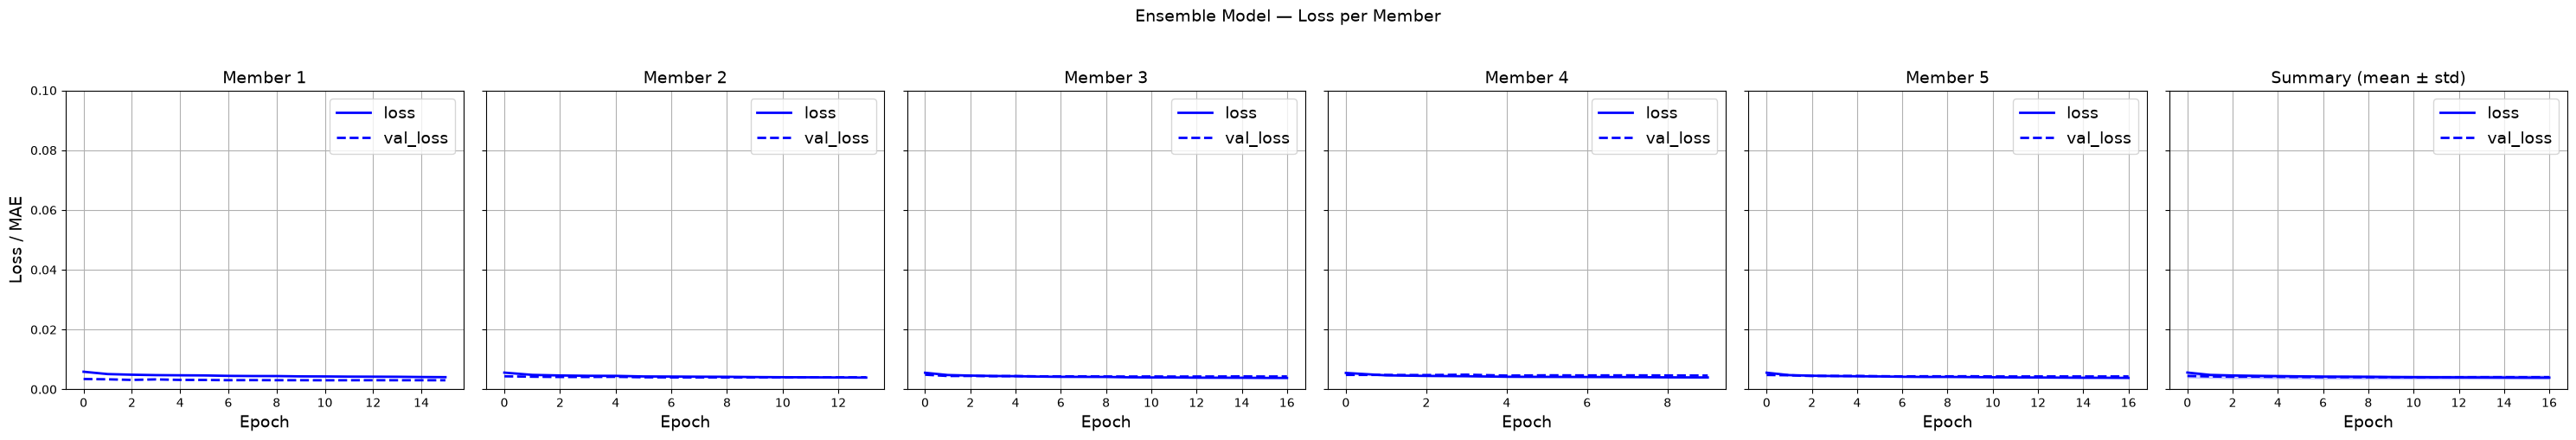

<Figure size 640x480 with 0 Axes>


==================== kfold_cyclestart: {'data_cut': 'kfold', 'pretrained_member': None} ====================

--- Member 1/5 ---
Epoch 1/100


I0000 00:00:1793217470.769958  441832 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_94793__.37


250/250 - 5s - 19ms/step - loss: 0.0058 - val_loss: 0.0036 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0051 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0049 - val_loss: 0.0033 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0048 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0031 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0032 - learning_rate: 0.0010
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0031 - learning_rate:

I0000 00:00:1793217486.863367  441831 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_113528__.37


...

250/250 - 5s - 19ms/step - loss: 0.0052 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0047 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 7/100

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0044 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0043 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0043 - learnin

I0000 00:00:1793217517.429715  441829 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_149111__.37


250/250 - 5s - 19ms/step - loss: 0.0053 - val_loss: 0.0052 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0049 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0048 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 10/100
250/250 - 1s - 3ms/step - loss: 0.0040 - val_loss: 0.0046 - learning_rate: 

I0000 00:00:1793217537.062614  441831 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_172750__.37


250/250 - 5s - 19ms/step - loss: 0.0054 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 3ms/step - loss: 0.0045 - val_loss: 0.0047 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 7/100

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 3ms/step - loss: 0.0043 - val_loss: 0.0045 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 3ms/step - loss: 0.0041 - val_loss: 0.0044 - learning_rate: 5.0000e-04
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0002500000

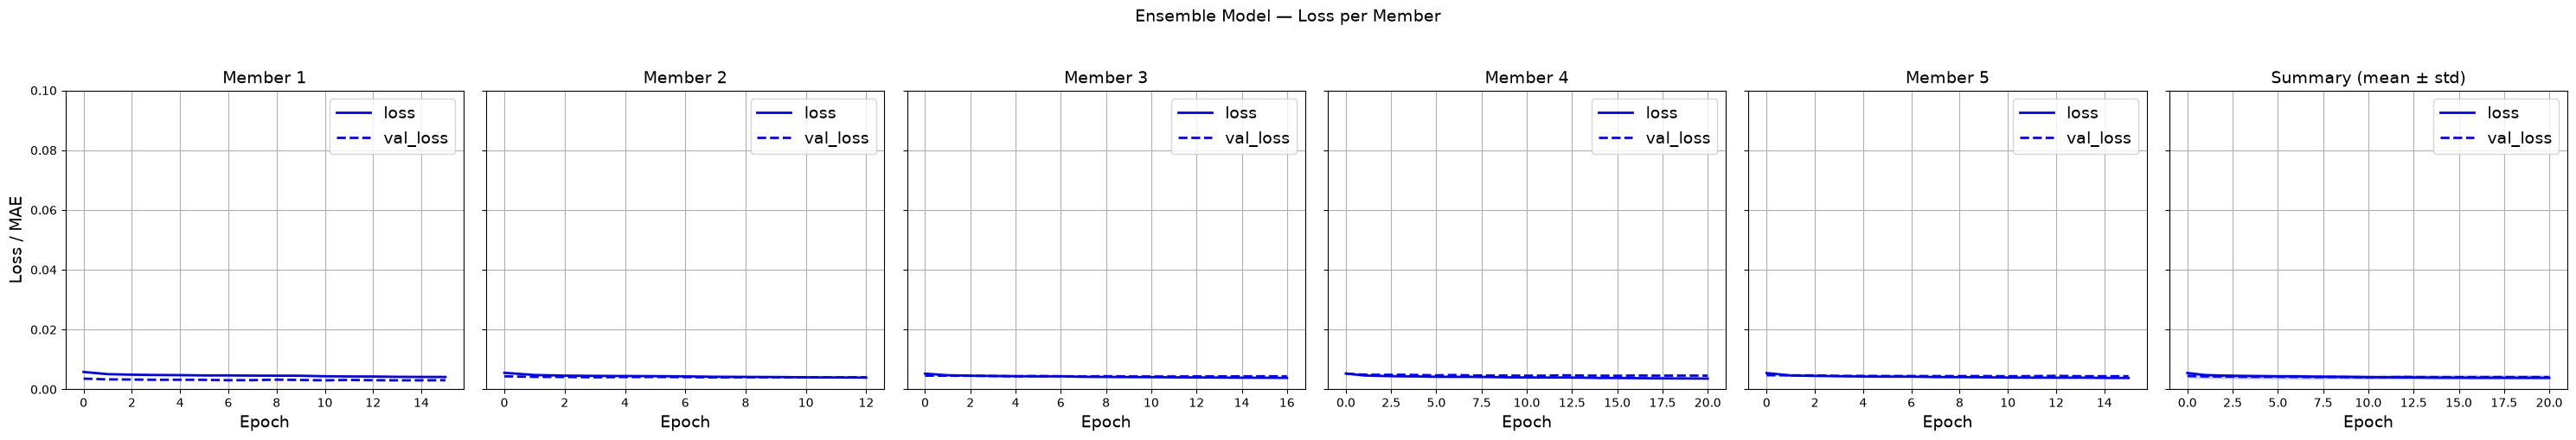

<Figure size 640x480 with 0 Axes>

In [3]:
X_fit, _ = znn.catalog_to_XY(train.iloc[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG)

for name, settings in TRAIN.items():
    model_files[name] = os.path.join(TEST_DIR, f"{name}_{MODEL_NAME}")
    if os.path.exists(model_files[name]):
        print(f"{name}: already trained, {model_files[name]}")
        continue
    print(f"\n==================== {name}: {settings} ====================")
    trained_models, histories = znn.train_ensembles(
        znn.build_model, X_fit, z_ref[idx_fit], N_SPLITS=N_SPLITS, EPOCHS=EPOCHS, random_state=SEED,
        pretraining=PRETRAINING, **settings,
    )
    znn.plot_ensemble_losses(histories, ylim=(0, 0.1))
    plt.suptitle(name, y=1.08)
    plt.show()
    znn.save_ensemble_file(model_files[name], trained_models, BANDS, REF_BAND, FEATURE_CONFIG)

## Predict the held-out objects

Every ensemble with the same `N_SAMPLES` noise draws (same seed). Cached in `TEST_DIR`.

In [4]:
def heldout_predictions(name):
    # Per held-out object: p(z) mean and std, and the std split into members' disagreement and noise draws.
    cache = os.path.join(TEST_DIR, f"heldout_{name}.npz")
    if os.path.exists(cache):
        return dict(np.load(cache))
    trained_models, features = znn.load_ensemble_file(model_files[name])
    errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
    pz, components = znn.ensemble_predict_resampled(
        trained_models, val, errors, N_SAMPLES, np.random.default_rng(NOISE_SEED), **features, return_components=True
    )
    out = {
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
        "model_std": components["model"],
        "photometric_std": components["photometric"],
    }
    np.savez(cache, **out)
    return out


ARMS = list(SAVED) + list(TRAIN)
preds = {}
for name in ARMS:
    print("held-out predictions:", name)
    preds[name] = heldout_predictions(name)

held-out predictions: baseline
held-out predictions: noisytrain
held-out predictions: kfold_samestart
held-out predictions: kfold_cyclestart


## Scores

The challenge's seven metrics (as in `pz_challenge_results.ipynb`, with the mean as the point estimate) and their tier points, per ensemble and held-out subset, plus:
- `width/scatter`: median p(z) σ/(1+z) over the biweight scatter; 1 for p(z)s as wide as the actual errors, below 1 for overconfident ones;
- `model σ`, `photometric σ`: median of the two parts of the p(z) σ (they add in quadrature). `model σ` measures how different the members are;
- `pit_outlier_direct`: the PIT outlier rate computed directly (the scored `outlier` comes from a spline fit that breaks down when PIT piles up at 0 or 1).

Lower is better for all metrics except the points. Compare differences between ensembles with the `baseline` / `kfold_cyclestart` gap.

In [5]:
def scores(z, d, m):
    dz = (d["mean"][m] - z[m]) / (1 + z[m])
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pz = qp.Ensemble(qp.stats.norm, data={"loc": d["mean"][m, None], "scale": d["std"][m, None]})
    pit = PIT(pz, z[m])
    values = {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }
    points = sum(lo <= float(values[k]) <= hi for k, ranges in scoring.metric_dict.items() for lo, hi in ranges)
    extra = {
        "pit_outlier_direct": np.mean((pit.pit_samps < 0.0001) | (pit.pit_samps > 0.9999)),
        "width/scatter": np.median(d["std"][m] / (1 + z[m])) / scatter,
        "model σ": np.median(d["model_std"][m]),
        "photometric σ": np.median(d["photometric_std"][m]),
        "points": points,
    }
    return values | extra, pit.pit_samps


z_val = z_ref[idx_val]
rows, pits = {}, {}
for name in ARMS:
    for subset, mask in subsets.items():
        rows[(subset, name)], pits[(subset, name)] = scores(z_val, preds[name], mask[idx_val])

table = pd.DataFrame(rows).T
table.index.names = ["subset", "ensemble"]
n_max = sum(len(r) for r in scoring.metric_dict.values())
print(f"points out of {n_max}")
table.round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


points out of 21


,,mean,std,abs_outlier_rate,ks,CvM,ksamp,outlier,pit_outlier_direct,width/scatter,model σ,photometric σ,points
subset,ensemble,,,,,,,,,,,,
all,baseline,0.0034,0.0187,0.0264,0.1198,141.7389,593.3535,-5.077100e+01,0.0458,0.7309,0.0164,0.0151,17.0
spec,baseline,0.0029,0.0130,0.0012,0.1121,76.7763,280.0033,2.440000e-02,0.0210,0.8024,0.0134,0.0104,21.0
COSMOS-only,baseline,0.0075,0.0479,0.0702,0.1652,77.8735,360.6129,-6.895544e+14,0.0889,0.6404,0.0282,0.0484,16.0
all,noisytrain,0.0049,0.0213,0.0275,0.2059,350.5984,1413.7171,-2.004434e+02,0.0646,0.5710,0.0148,0.0138,14.0
spec,noisytrain,0.0045,0.0153,0.0017,0.2213,268.6222,1018.4019,1.071000e-01,0.0456,0.5796,0.0103,0.0094,18.0
COSMOS-only,noisytrain,0.0073,0.0493,0.0724,0.1833,94.0003,433.6953,1.005965e+15,0.0976,0.5951,0.0288,0.0448,16.0
all,kfold_samestart,0.0018,0.0198,0.0261,0.1137,106.8880,556.6557,1.028000e-01,0.0524,0.6454,0.0141,0.0159,20.0
spec,kfold_samestart,0.0013,0.0140,0.0009,0.0907,46.8852,251.6324,6.320000e-02,0.0318,0.6982,0.0107,0.0105,21.0
COSMOS-only,kfold_samestart,0.0060,0.0486,0.0698,0.1549,66.3605,324.1090,2.169043e+02,0.0881,0.6476,0.0264,0.0512,16.0


In [6]:
# the key numbers on all held-out objects, relative to the saved baseline
key = ["std", "abs_outlier_rate", "ks", "width/scatter", "model σ", "points"]
rel = table.xs("all", level="subset")[key].copy()
for col in ["std", "abs_outlier_rate", "ks", "model σ"]:
    rel[col + " vs baseline"] = rel[col] / rel.loc["baseline", col] - 1
rel.round(4)

,std,abs_outlier_rate,ks,width/scatter,model σ,points,std vs baseline,abs_outlier_rate vs baseline,ks vs baseline,model σ vs baseline
ensemble,,,,,,,,,,
baseline,0.0187,0.0264,0.1198,0.7309,0.0164,17.0,0.0000,0.0000,0.0000,0.0000
noisytrain,0.0213,0.0275,0.2059,0.5710,0.0148,14.0,0.1403,0.0417,0.7190,-0.0965
kfold_samestart,0.0198,0.0261,0.1137,0.6454,0.0141,20.0,0.0610,-0.0114,-0.0504,-0.1359
kfold_cyclestart,0.0197,0.0263,0.1392,0.6514,0.0153,20.0,0.0533,-0.0038,0.1627,-0.0644


## PIT

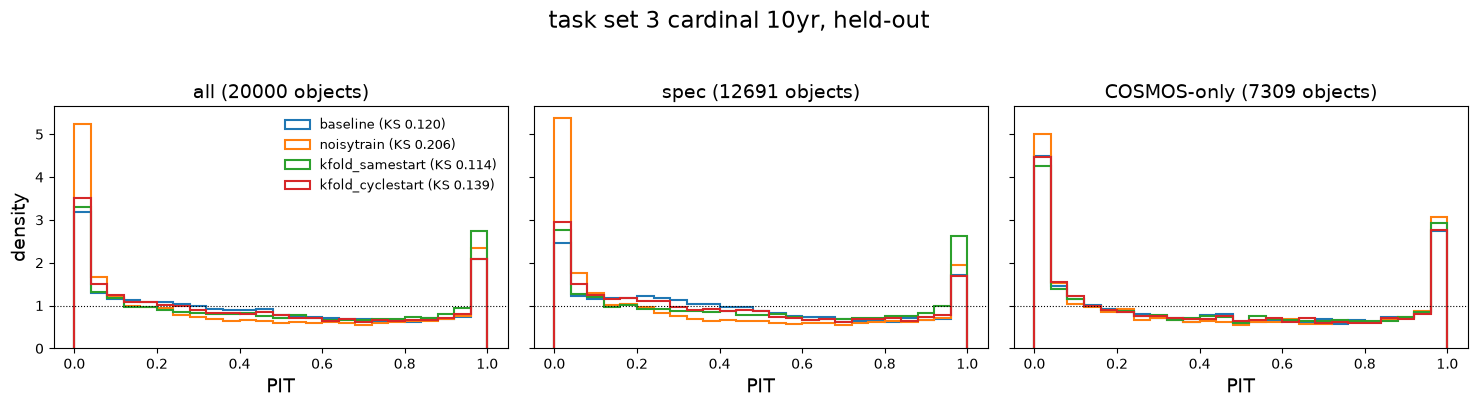

In [7]:
pit_bins = np.linspace(0, 1, 26)
fig, axes = plt.subplots(1, len(subsets), figsize=(5 * len(subsets), 4), sharey=True, squeeze=False)
for ax, subset in zip(axes[0], subsets):
    for name in ARMS:
        ax.hist(pits[(subset, name)], pit_bins, density=True, histtype="step", lw=1.5,
                label=f"{name} (KS {table.loc[(subset, name), 'ks']:.3f})")
    ax.axhline(1, color="k", lw=0.8, ls=":")
    ax.set_title(f"{subset} ({subsets[subset][idx_val].sum()} objects)")
    ax.set_xlabel("PIT")
axes[0, 0].set_ylabel("density")
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle(f"task set {TASKSET} {SIM} {SCENARIO}, held-out", y=1.02)
fig.tight_layout()
plt.show()